In [33]:
import femm
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import subprocess
import time
from pathlib import Path

# =====================================================
# 1. SETTINGS
# =====================================================

model_path = Path("FEMM_Test_Trafo.fem").resolve()

primary_name = "Primary"
secondary_name = "Secondary"

# Primary current sweep (peak values)
currents = np.linspace(0.001, 1000, 20)


In [34]:
# =====================================================
# 2. CONNECT TO FEMM
# =====================================================

# FEMM must already be running through Wine on port 5000.
# Reuse an existing session if you have already connected.

if "session" not in globals():
    session = femm.FemmSession(
        host="127.0.0.1",
        port=5000,
        launch=False
    )

# Convert Linux path to Windows path
wine_path = subprocess.check_output(
    ["winepath", "-w", str(model_path)],
    text=True
).strip()

# Open transformer model
session.opendocument(wine_path)

In [35]:
# =====================================================
# 3. INITIALIZE ARRAYS
# =====================================================

I1_data = []
V1_data = []
Psi1_data = []

I2_data = []
V2_data = []
Psi2_data = []

P1_data = []
Q1_data = []
S1_data = []

P2_data = []
Q2_data = []
S2_data = []



In [36]:
# =====================================================
# 4. CURRENT SWEEP
# =====================================================

for I in currents:

    print(f"\nSimulating I = {I:.3f} A...", flush=True)

    start = time.perf_counter()

    # Set primary current
    session.mi_modifycircprop(primary_name, 1, float(I))

    # Solve AC magnetic problem
    session.mi_analyze(1)

    # Load results
    session.mi_loadsolution()

    # ---------------------------------
    # Read circuit properties
    # ---------------------------------

    primary = session.mo_getcircuitproperties(primary_name)
    secondary = session.mo_getcircuitproperties(secondary_name)

    # Validate results
    if len(primary) != 3 or len(secondary) != 3:
        raise RuntimeError(
            f"Invalid circuit data at I = {I:.3f} A:\n"
            f"Primary: {primary}\n"
            f"Secondary: {secondary}"
        )

    I1, V1, Psi1 = primary
    I2, V2, Psi2 = secondary

    # Check whether FEMM returned the expected primary current
    if not np.isclose(I1, I, rtol=1e-3, atol=1e-3):
        raise RuntimeError(
            f"Primary current mismatch at {I:.3f} A: "
            f"FEMM returned {I1!r} A"
        )

    # ---------------------------------
    # Calculate complex power
    # ---------------------------------

    # FEMM AC current and voltage are peak phasors
    S1_complex = V1 * np.conj(I1) / 2
    S2_complex = V2 * np.conj(I2) / 2

    # ---------------------------------
    # Save results
    # ---------------------------------

    I1_data.append(I1)
    V1_data.append(V1)
    Psi1_data.append(Psi1)

    I2_data.append(I2)
    V2_data.append(V2)
    Psi2_data.append(Psi2)

    P1_data.append(S1_complex.real)
    Q1_data.append(S1_complex.imag)
    S1_data.append(abs(S1_complex))

    P2_data.append(S2_complex.real)
    Q2_data.append(S2_complex.imag)
    S2_data.append(abs(S2_complex))

    # Close postprocessor
    session.mo_close()

    elapsed = time.perf_counter() - start

    print(
        f"Primary: |V| = {abs(V1):.2f} V, "
        f"|S| = {abs(S1_complex)/1e6:.4f} MVA"
    )

    print(
        f"Secondary: |V| = {abs(V2):.2f} V, "
        f"|S| = {abs(S2_complex)/1e6:.4f} MVA"
    )

    print(f"Time: {elapsed:.2f} s")


Simulating I = 0.001 A...
Primary: |V| = 5738325.20 V, |S| = 0.0029 MVA
Secondary: |V| = 580314.19 V, |S| = 580.3142 MVA
Time: 2.99 s

Simulating I = 52.633 A...
Primary: |V| = 5858343.36 V, |S| = 154.1697 MVA
Secondary: |V| = 590646.77 V, |S| = 590.6468 MVA
Time: 3.60 s

Simulating I = 105.264 A...
Primary: |V| = 5955234.59 V, |S| = 313.4361 MVA
Secondary: |V| = 598713.78 V, |S| = 598.7138 MVA
Time: 2.84 s

Simulating I = 157.896 A...
Primary: |V| = 6036840.93 V, |S| = 476.5952 MVA
Secondary: |V| = 605296.04 V, |S| = 605.2960 MVA
Time: 3.24 s

Simulating I = 210.527 A...
Primary: |V| = 6107691.70 V, |S| = 642.9173 MVA
Secondary: |V| = 610843.82 V, |S| = 610.8438 MVA
Time: 3.44 s

Simulating I = 263.159 A...
Primary: |V| = 6170710.18 V, |S| = 811.9378 MVA
Secondary: |V| = 615645.50 V, |S| = 615.6455 MVA
Time: 3.70 s

Simulating I = 315.790 A...
Primary: |V| = 6227920.19 V, |S| = 983.3580 MVA
Secondary: |V| = 619898.09 V, |S| = 619.8981 MVA
Time: 3.68 s

Simulating I = 368.422 A...
Pri

In [37]:
# =====================================================
# 5. CREATE DATAFRAME
# =====================================================

results = pd.DataFrame({
    "I_primary_set_A": currents,
    "I_primary_A": I1_data,
    "V_primary_V": V1_data,
    "Psi_primary_Wb": Psi1_data,
    "I_secondary_A": I2_data,
    "V_secondary_V": V2_data,
    "Psi_secondary_Wb": Psi2_data,
    "P_primary_W": P1_data,
    "Q_primary_var": Q1_data,
    "S_primary_VA": S1_data,
    "P_secondary_W": P2_data,
    "Q_secondary_var": Q2_data,
    "S_secondary_VA": S2_data
})

display(results)

# Save numerical results
results.to_csv("transformer_sweep.csv", index=False)

,I_primary_set_A,I_primary_A,V_primary_V,Psi_primary_Wb,I_secondary_A,V_secondary_V,Psi_secondary_Wb,P_primary_W,Q_primary_var,S_primary_VA,P_secondary_W,Q_secondary_var,S_secondary_VA
0,0.001000,0.001000,4.706355e+04+5.738132e+06j,18265.042079- 149.807708j,2000,18020.699842+580034.322119j,1846.306591- 14.975247j,2.353177e+01,2.869066e+03,2.869163e+03,1.802070e+07,5.800343e+08,5.803142e+08
1,52.632526,52.632526,4.220304e+04+5.858191e+06j,18647.202187- 123.181931j,2000,17184.610138+590396.722776j,1879.291136- 12.313891j,1.110626e+06,1.541657e+08,1.541697e+08,1.718461e+07,5.903967e+08,5.906468e+08
2,105.264053,105.264053,4.002084e+04+5.955100e+06j,18955.672406- 105.081450j,2000,16616.412393+598483.158250j,1905.031060- 10.505261j,2.106378e+06,3.134290e+08,3.134361e+08,1.661641e+07,5.984832e+08,5.987138e+08
3,157.895579,157.895579,3.935313e+04+6.036713e+06j,19215.453210- 91.801770j,2000,16199.704614+605079.224139j,1926.026990- 9.178839j,3.106843e+06,4.765851e+08,4.765952e+08,1.619970e+07,6.050792e+08,6.052960e+08
4,210.527105,210.527105,3.966593e+04+6.107563e+06j,19440.976512- 81.643128j,2000,15881.071072+610637.341894j,1943.719028- 8.164597j,4.175377e+06,6.429038e+08,6.429173e+08,1.588107e+07,6.106373e+08,6.108438e+08
5,263.158632,263.158632,4.064967e+04+6.170576e+06j,19641.554373- 73.620162j,2000,15629.538482+615447.072983j,1959.028878- 7.363944j,5.348656e+06,8.119202e+08,8.119378e+08,1.562954e+07,6.154471e+08,6.156455e+08
6,315.790158,315.790158,4.210908e+04+6.227778e+06j,19823.632526- 67.111283j,2000,15425.562282+619706.136668j,1972.585898- 6.714667j,6.648816e+06,9.833355e+08,9.833580e+08,1.542556e+07,6.197061e+08,6.198981e+08
7,368.421684,368.421684,4.392617e+04+6.280633e+06j,19991.875094- 61.740953j,2000,15257.329193+623554.883422j,1984.836840- 6.179165j,8.091677e+06,1.156961e+09,1.156989e+09,1.525733e+07,6.235549e+08,6.237415e+08
8,421.053211,421.053211,4.600921e+04+6.330218e+06j,20149.708405- 57.217163j,2000,15115.655219+627094.884363j,1996.105013- 5.728203j,9.686162e+06,1.332679e+09,1.332714e+09,1.511566e+07,6.270949e+08,6.272770e+08
9,473.684737,473.684737,4.829976e+04+6.377332e+06j,20299.677362- 53.353895j,2000,14994.689847+630400.402891j,2006.626805- 5.343158j,1.143943e+07,1.510422e+09,1.510466e+09,1.499469e+07,6.304004e+08,6.305787e+08


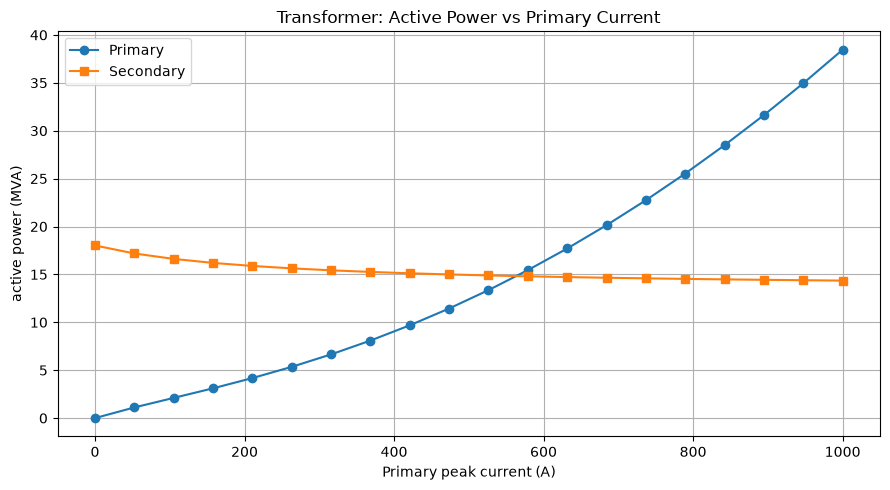

In [41]:
# =====================================================
# 6. PLOT ACTIVE POWER
# =====================================================

plt.figure(figsize=(9, 5))

plt.plot(
    currents,
    np.array(P1_data) / 1e6,
    "o-",
    label="Primary"
)

plt.plot(
    currents,
    np.array(P2_data) / 1e6,
    "s-",
    label="Secondary"
)

plt.xlabel("Primary peak current (A)")
plt.ylabel("active power (MVA)")
plt.title("Transformer: Active Power vs Primary Current")

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

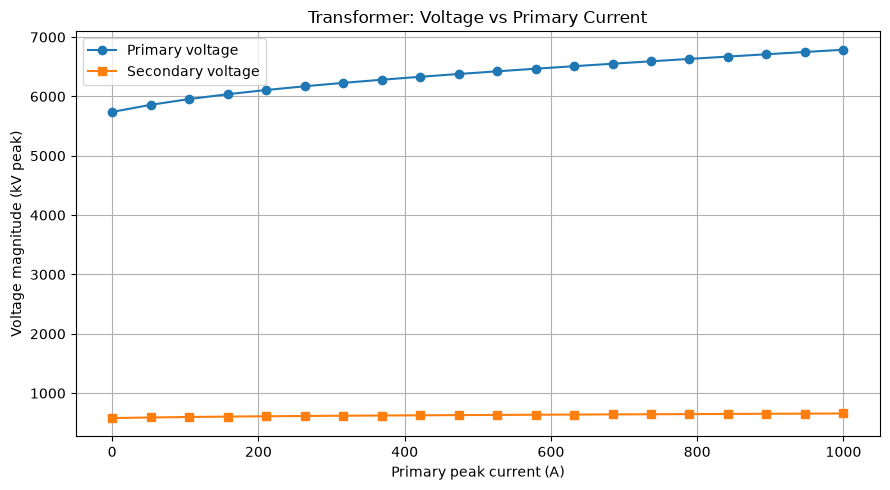

In [39]:
# =====================================================
# 7. PLOT VOLTAGES
# =====================================================

plt.figure(figsize=(9, 5))

plt.plot(
    currents,
    np.abs(V1_data) / 1000,
    "o-",
    label="Primary voltage"
)

plt.plot(
    currents,
    np.abs(V2_data) / 1000,
    "s-",
    label="Secondary voltage"
)

plt.xlabel("Primary peak current (A)")
plt.ylabel("Voltage magnitude (kV peak)")
plt.title("Transformer: Voltage vs Primary Current")

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

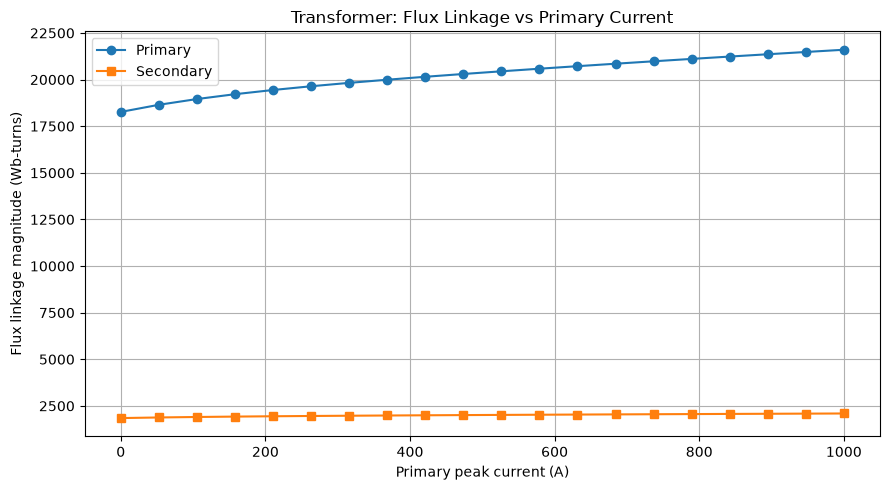

In [40]:
# =====================================================
# 8. PLOT FLUX LINKAGE
# =====================================================

plt.figure(figsize=(9, 5))

plt.plot(
    currents,
    np.abs(Psi1_data),
    "o-",
    label="Primary"
)

plt.plot(
    currents,
    np.abs(Psi2_data),
    "s-",
    label="Secondary"
)

plt.xlabel("Primary peak current (A)")
plt.ylabel("Flux linkage magnitude (Wb-turns)")
plt.title("Transformer: Flux Linkage vs Primary Current")

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()